# NinjaPhonetics E2: 4群ベンチマーク音響プロソディ指標の分布解析

- 対象コホート: UK-Native, US-Native, JP-Accented, JP-Mora-Forced (各 n=10)
- 比較指標:
  1. %V (母音占有率 [%])
  2. %C (子音占有率 [%])
  3. nPVI_clipped (30msフロア補正済み正規化母音変動指標)
  4. Schwa Median (弱母音中央値 [ms])
  5. Schwa P75 (弱母音第3四分位数 [ms])
  6. Stressed / Unstressed 平均長比

In [ ]:
!generate_benchmarks.py

!python evaluate_benchmarks.py

zsh:1: command not found: generate_benchmarks.py


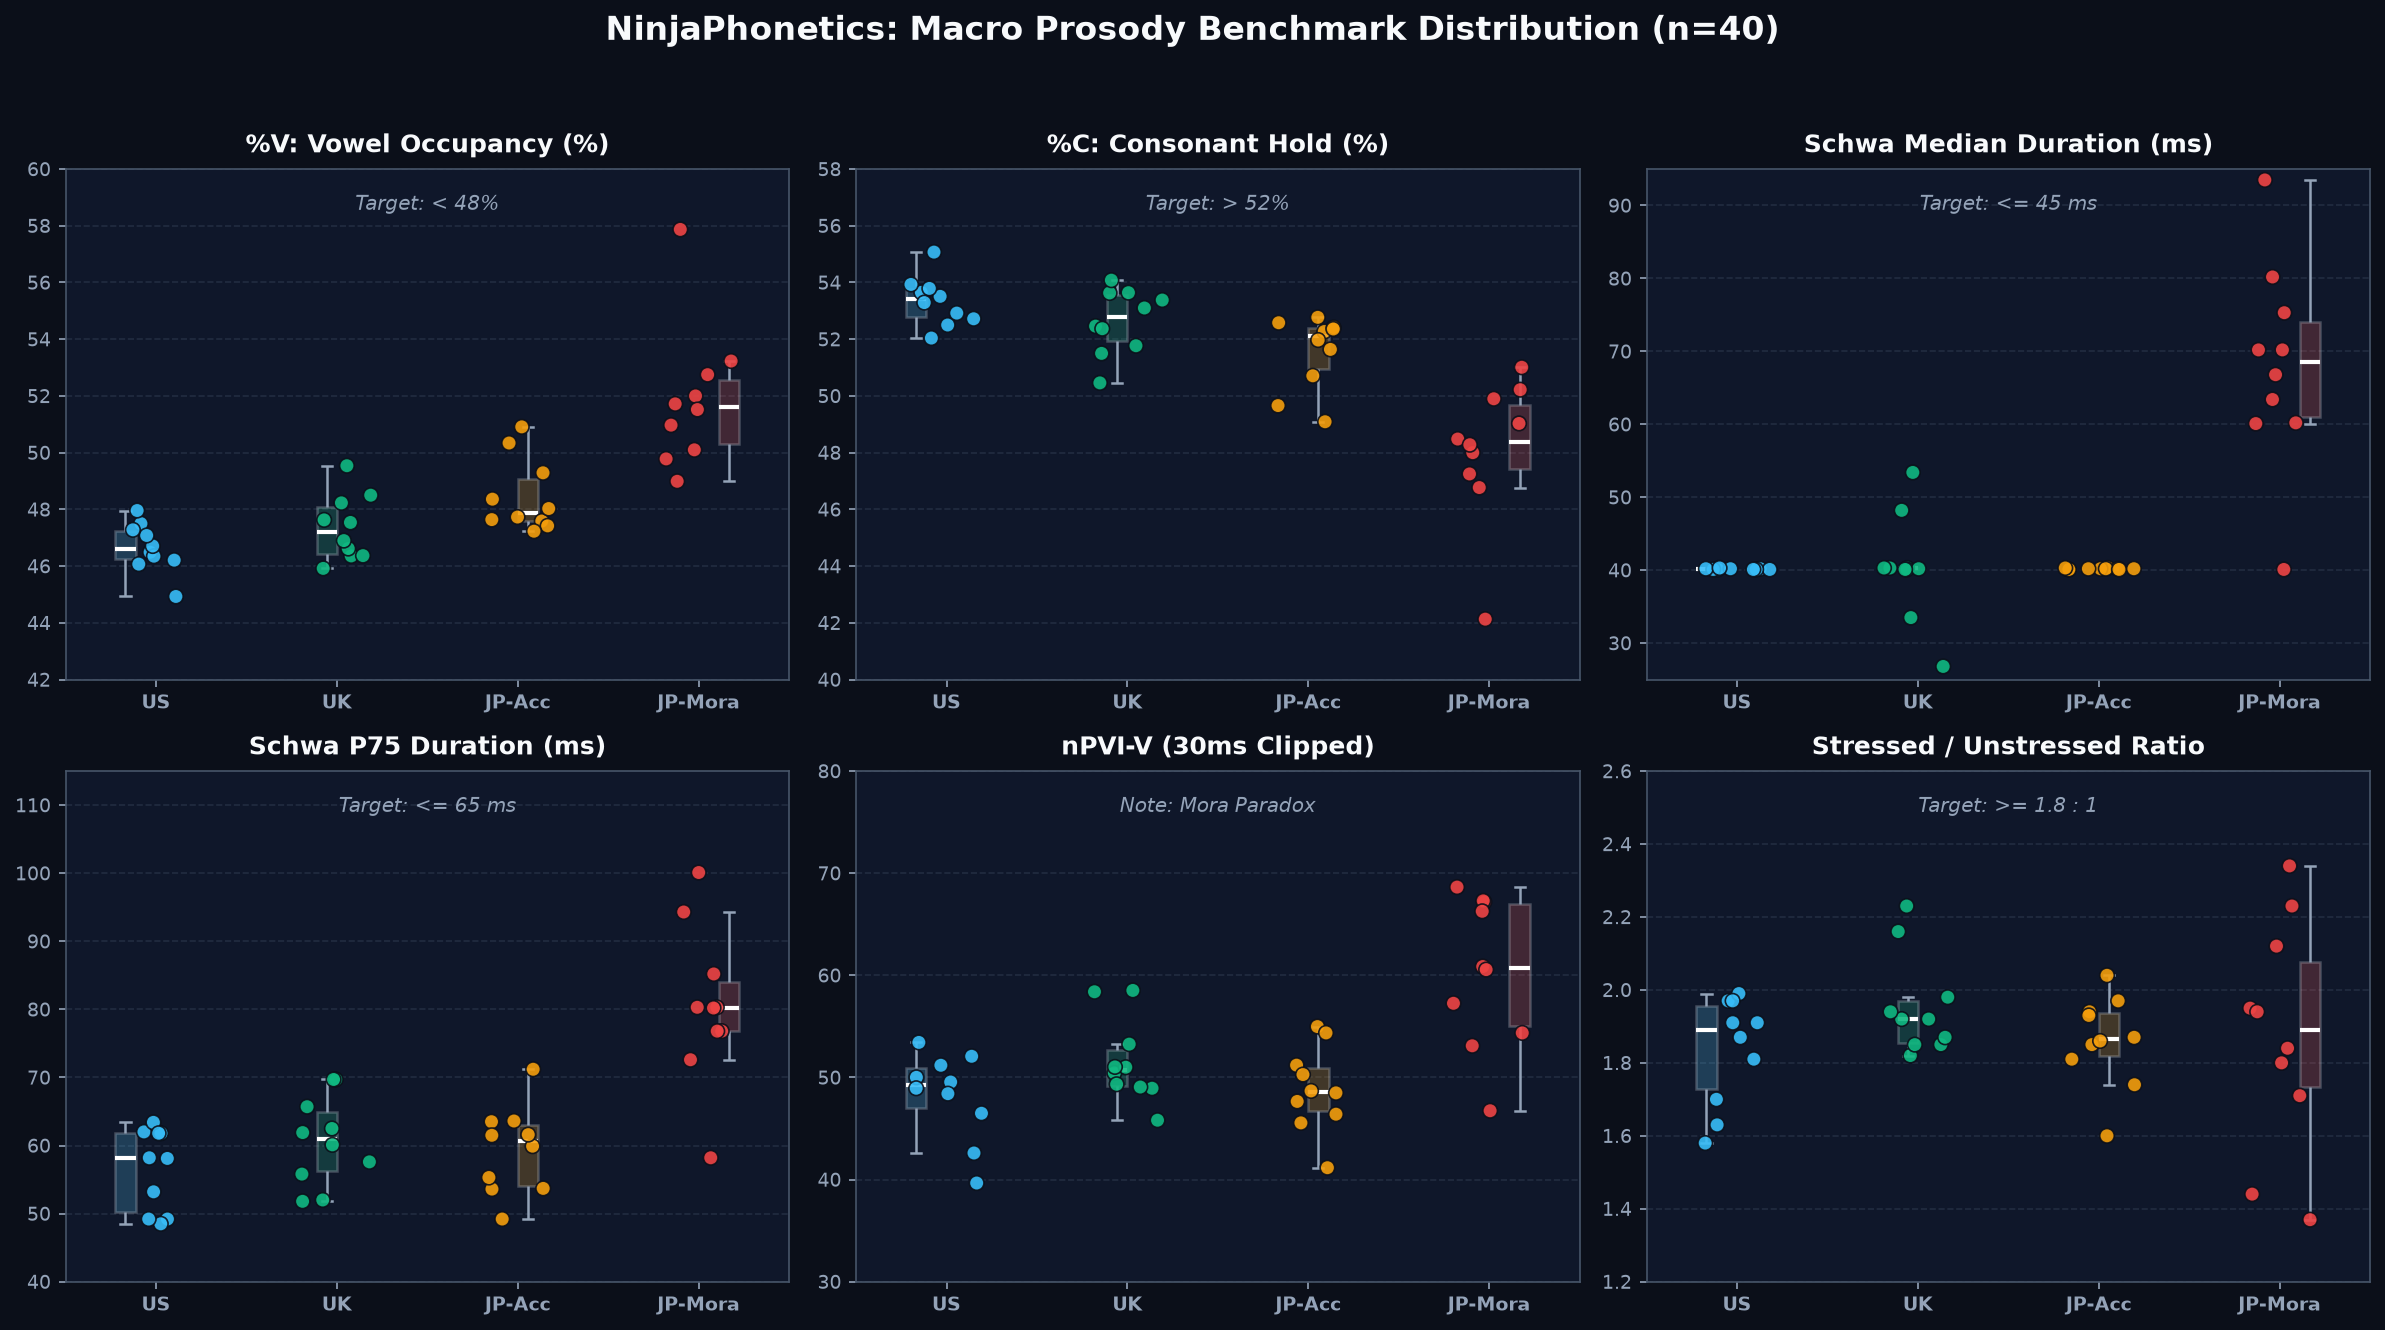

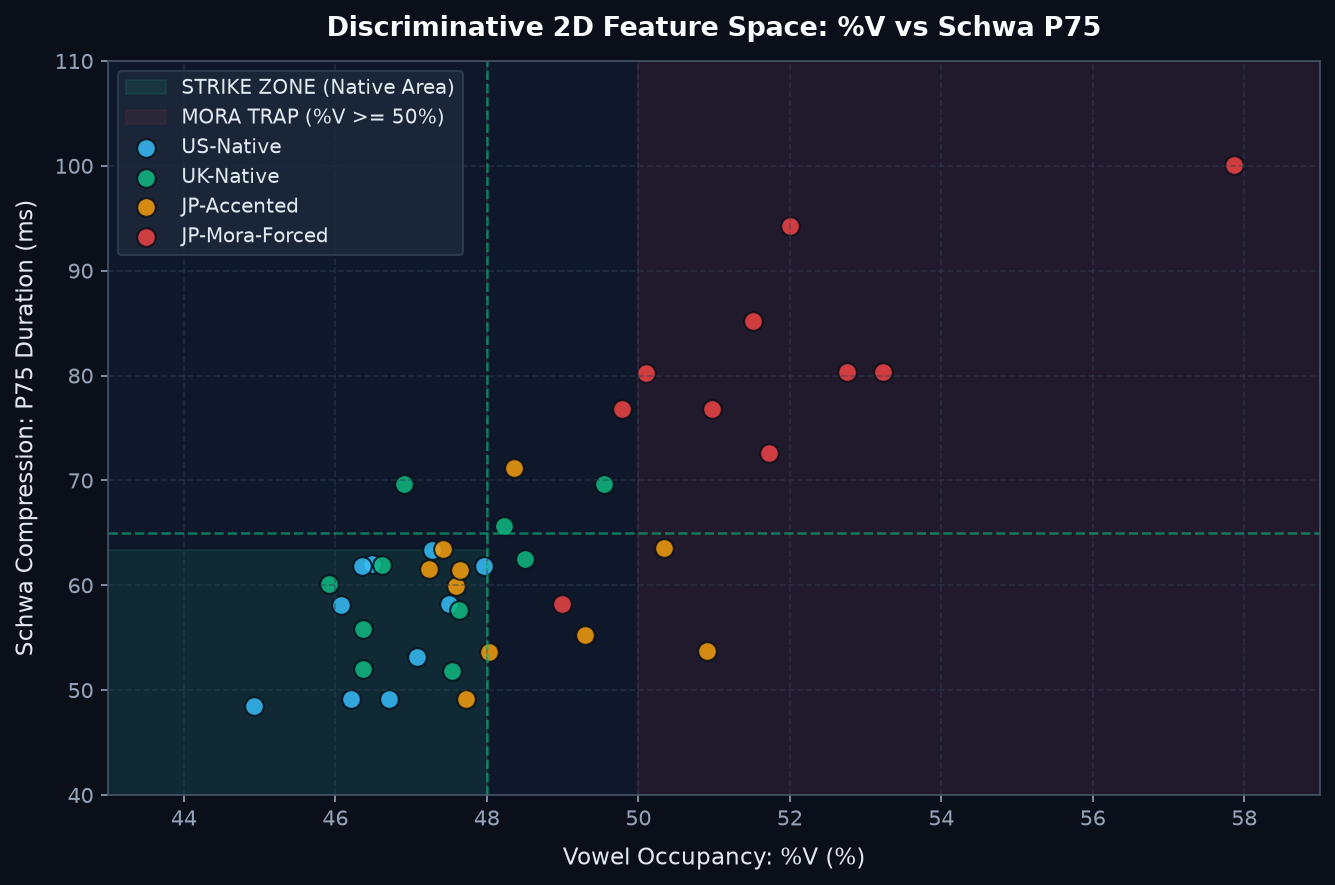

,Metric,Cohen's d (Native vs Mora)
2,schwa_median_ms,3.10
0,pct_v,2.96
1,pct_c,2.96
3,schwa_p75_ms,2.61
4,schwa_p90_ms,1.98
5,npvi_clipped,1.87
6,s_u_ratio_mean,0.09


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# スタイル・フォント設定（Spike2 / 暗色テーマに調和するダーク・クリーン設定）
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#475569'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#334155'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.5

# %%
# 1. データの読み込みとコホート順序の固定
df = pd.read_csv("benchmarks/benchmark_results.csv")

cohort_order = ["US-Native", "UK-Native", "JP-Accented", "JP-Mora-Forced"]
palette = {
    "US-Native": "#38BDF8",       # スカイブルー
    "UK-Native": "#10B981",       # エメラルドグリーン
    "JP-Accented": "#F59E0B",     # アンバー
    "JP-Mora-Forced": "#EF4444"   # レッド
}

# 欠損や順序を明示
df['cohort'] = pd.Categorical(df['cohort'], categories=cohort_order, ordered=True)

# %%
# 2. 6大指標の 2x3 グリッド・プロット (Boxplot + Strip / Swarm)
metrics_to_plot = [
    ("pct_v", "%V: Vowel Occupancy (%)", "Target: < 48%", (42, 60)),
    ("pct_c", "%C: Consonant Hold (%)", "Target: > 52%", (40, 58)),
    ("schwa_median_ms", "Schwa Median Duration (ms)", "Target: <= 45 ms", (25, 95)),
    ("schwa_p75_ms", "Schwa P75 Duration (ms)", "Target: <= 65 ms", (40, 115)),
    ("npvi_clipped", "nPVI-V (30ms Clipped)", "Note: Mora Paradox", (30, 80)),
    ("s_u_ratio_mean", "Stressed / Unstressed Ratio", "Target: >= 1.8 : 1", (1.2, 2.6))
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=150)
fig.patch.set_facecolor('#0B0F19')
axes = axes.flatten()

for idx, (col, title, subtitle, ylim) in enumerate(metrics_to_plot):
    ax = axes[idx]
    ax.set_facecolor('#0F172A')
    
    # 箱ひげ図 (hue='cohort' と legend=False を明示)
    sns.boxplot(
        data=df,
        x='cohort',
        y=col,
        hue='cohort',
        legend=False,
        order=cohort_order,
        palette=palette,
        ax=ax,
        width=0.45,
        boxprops=dict(alpha=0.25, edgecolor='#E2E8F0', linewidth=1.2),
        whiskerprops=dict(color='#94A3B8', linewidth=1.2),
        capprops=dict(color='#94A3B8', linewidth=1.2),
        medianprops=dict(color='#FFFFFF', linewidth=2.0),
        showfliers=False
    )
    
    # 生データ点 (hue='cohort' と legend=False を明示)
    sns.stripplot(
        data=df,
        x='cohort',
        y=col,
        hue='cohort',
        legend=False,
        order=cohort_order,
        palette=palette,
        ax=ax,
        size=7,
        jitter=0.2,
        alpha=0.9,
        edgecolor='#0B0F19',
        linewidth=0.8
    )
    
    ax.set_title(title, fontsize=12, fontweight='bold', color='#F8FAFC', pad=8)
    ax.text(0.5, 0.92, subtitle, transform=ax.transAxes, ha='center',
            fontsize=9.5, color='#94A3B8', style='italic')
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_ylim(ylim)
    ax.tick_params(colors='#94A3B8', labelsize=9)
    ax.grid(True, axis='y')
    
    # set_ticks を明示してからラベルを指定 (UserWarning 回避)
    labels = ["US", "UK", "JP-Acc", "JP-Mora"]
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=0, fontweight='bold')

plt.suptitle("NinjaPhonetics: Macro Prosody Benchmark Distribution (n=40)", 
             fontsize=16, fontweight='bold', color='#F8FAFC', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("benchmarks/prosody_distribution.png", facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()

# %%
# 3. 2D散布図による「真のストライクゾーン（%V vs Schwa P75）」の可視化
fig, ax = plt.subplots(figsize=(9, 6), dpi=150)
fig.patch.set_facecolor('#0B0F19')
ax.set_facecolor('#0F172A')

# ストライクゾーン（矩形シェード）
ax.axvspan(42.0, 48.0, ymin=0, ymax=(65.0 - 40)/(115.0 - 40), 
           color='#10B981', alpha=0.12, label='STRIKE ZONE (Native Area)')
ax.axvline(48.0, color='#10B981', linestyle='--', linewidth=1.2, alpha=0.6)
ax.axhline(65.0, color='#10B981', linestyle='--', linewidth=1.2, alpha=0.6)

# モーラトラップ（危険領域）
ax.axvspan(50.0, 60.0, color='#EF4444', alpha=0.08, label='MORA TRAP (%V >= 50%)')

# 各サンプルの散布
for cohort_name in cohort_order:
    sub = df[df['cohort'] == cohort_name]
    ax.scatter(
        sub['pct_v'], sub['schwa_p75_ms'],
        color=palette[cohort_name],
        label=cohort_name,
        s=80, alpha=0.85, edgecolors='#0B0F19', linewidth=1.0
    )

ax.set_title("Discriminative 2D Feature Space: %V vs Schwa P75", fontsize=13, fontweight='bold', color='#F8FAFC', pad=12)
ax.set_xlabel("Vowel Occupancy: %V (%)", fontsize=11, color='#E2E8F0', labelpad=8)
ax.set_ylabel("Schwa Compression: P75 Duration (ms)", fontsize=11, color='#E2E8F0', labelpad=8)
ax.set_xlim(43, 59)
ax.set_ylim(40, 110)
ax.tick_params(colors='#94A3B8')
ax.grid(True)

legend = ax.legend(frameon=True, facecolor='#1E293B', edgecolor='#334155', fontsize=9.5)
for text in legend.get_texts():
    text.set_color('#E2E8F0')

plt.tight_layout()
plt.savefig("benchmarks/prosody_2d_strike_zone.png", facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()

# %%
# 4. 効果量 (Cohen's d) による指標の判別力ランキング算出
def cohens_d(group1, group2):
    n1, n2 = len(group1), len(group2)
    s1, s2 = np.var(group1, ddof=1), np.var(group2, ddof=1)
    s_pooled = np.sqrt(((n1 - 1) * s1 + (n2 - 1) * s2) / (n1 + n2 - 2))
    return abs(np.mean(group1) - np.mean(group2)) / s_pooled

native_df = df[df['cohort'].isin(["US-Native", "UK-Native"])]
mora_df = df[df['cohort'] == "JP-Mora-Forced"]

d_scores = []
cols_to_evaluate = ["pct_v", "pct_c", "schwa_median_ms", "schwa_p75_ms", "schwa_p90_ms", "npvi_clipped", "s_u_ratio_mean"]

for c in cols_to_evaluate:
    d_val = cohens_d(native_df[c], mora_df[c])
    d_scores.append({"Metric": c, "Cohen's d (Native vs Mora)": round(d_val, 2)})

ranking_df = pd.DataFrame(d_scores).sort_values(by="Cohen's d (Native vs Mora)", ascending=False)
ranking_df

In [3]:
import numpy as np
import scipy.stats as stats
import matplotlib.patches as patches

def get_interval_stats(data, confidence=0.95):
    """Calculates Mean, 95% CI of Mean, and 95% Prediction/Reference Interval."""
    a = np.array(data)
    n = len(a)
    mean = np.mean(a)
    se = stats.sem(a)
    std = np.std(a, ddof=1)
    
    t_val = stats.t.ppf((1 + confidence) / 2., n - 1)
    
    # 95% CI of the population mean
    ci_low = mean - t_val * se
    ci_high = mean + t_val * se
    
    # 95% Prediction Interval (where a single new native talker is expected to land)
    pi_low = mean - t_val * std * np.sqrt(1 + 1/n)
    pi_high = mean + t_val * std * np.sqrt(1 + 1/n)
    
    return {
        "mean": mean,
        "ci_95": (ci_low, ci_high),
        "pi_95": (pi_low, pi_high),
        "percentile_95": (np.percentile(a, 2.5), np.percentile(a, 97.5))
    }

# Pool US and UK Native speakers as the benchmark ground truth
native_pool = df[df['cohort'].isin(["US-Native", "UK-Native"])]

for col in ["pct_v", "pct_c", "schwa_p75_ms", "s_u_ratio_mean"]:
    st = get_interval_stats(native_pool[col])
    print(f"[{col}]")
    print(f"  Mean: {st['mean']:.2f}")
    print(f"  95% CI (Mean) : [{st['ci_95'][0]:.2f}, {st['ci_95'][1]:.2f}]")
    print(f"  95% Strike Ref: [{st['pi_95'][0]:.2f}, {st['pi_95'][1]:.2f}]")

[pct_v]
  Mean: 47.01
  95% CI (Mean) : [46.52, 47.50]
  95% Strike Ref: [44.76, 49.25]
[pct_c]
  Mean: 52.99
  95% CI (Mean) : [52.50, 53.48]
  95% Strike Ref: [50.75, 55.24]
[schwa_p75_ms]
  Mean: 58.61
  95% CI (Mean) : [55.60, 61.62]
  95% Strike Ref: [44.81, 72.41]
[s_u_ratio_mean]
  Mean: 1.89
  95% CI (Mean) : [1.82, 1.97]
  95% Strike Ref: [1.57, 2.22]


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

def draw_confidence_ellipse(x, y, ax, n_std=2.447, facecolor='#10B981', alpha=0.15, **kwargs):
    """
    Draws an exact bivariate normal confidence/tolerance ellipse using PCA/eigen-decomposition.
    n_std = 2.447 corresponds to ~95% coverage for 2 degrees of freedom (sqrt(chi2.ppf(0.95, 2))).
    """
    x = np.asarray(x)
    y = np.asarray(y)
    
    cov = np.cov(x, y)
    vals, vecs = np.linalg.eigh(cov)
    
    # Sort eigenvalues/eigenvectors descending
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    
    # Orientation angle in degrees
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    
    # Semi-major and semi-minor axes radii (scaled by n_std)
    width, height = 2 * n_std * np.sqrt(np.maximum(vals, 0))
    
    ellipse = Ellipse(
        xy=(np.mean(x), np.mean(y)),
        width=width,
        height=height,
        angle=theta,
        facecolor=facecolor,
        alpha=alpha,
        **kwargs
    )
    return ax.add_patch(ellipse)

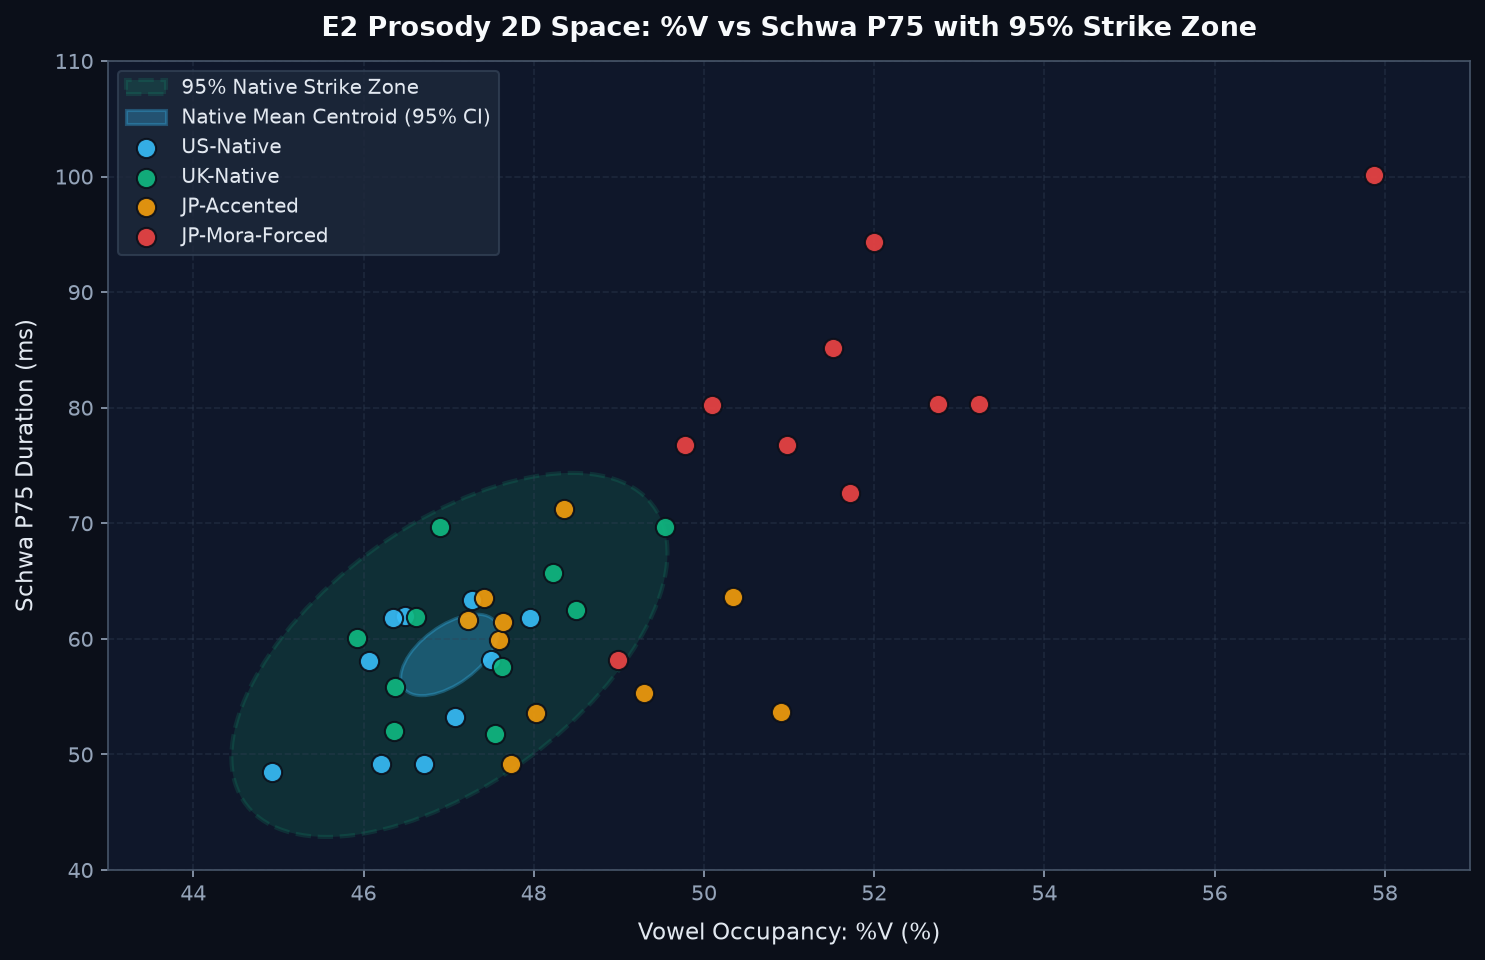

In [6]:
fig, ax = plt.subplots(figsize=(10, 6.5), dpi=150)
fig.patch.set_facecolor('#0B0F19')
ax.set_facecolor('#0F172A')

# 1. Native pooled reference (US + UK)
native_pool = df[df['cohort'].isin(["US-Native", "UK-Native"])]

# 2. Draw 95% Joint Strike Zone (Tolerance Ellipse: n_std = 2.447)
draw_confidence_ellipse(
    native_pool['pct_v'], 
    native_pool['schwa_p75_ms'], 
    ax, 
    n_std=2.447, 
    facecolor='#10B981',
    alpha=0.15,
    edgecolor='#10B981', 
    linestyle='--', 
    linewidth=2.0, 
    label='95% Native Strike Zone'
)

# 3. Optional: Inner Bullseye (Mean Centroid 95% CI: n_std / sqrt(N))
draw_confidence_ellipse(
    native_pool['pct_v'], 
    native_pool['schwa_p75_ms'], 
    ax, 
    n_std=2.447 / np.sqrt(len(native_pool)), 
    facecolor='#38BDF8',
    alpha=0.30,
    edgecolor='#38BDF8', 
    linestyle='-', 
    linewidth=1.5, 
    label='Native Mean Centroid (95% CI)'
)

# 4. Scatter points by cohort
for cohort_name in cohort_order:
    sub = df[df['cohort'] == cohort_name]
    ax.scatter(
        sub['pct_v'], sub['schwa_p75_ms'],
        color=palette[cohort_name],
        label=cohort_name,
        s=85, alpha=0.9, edgecolors='#0B0F19', linewidth=1.0,
        zorder=3
    )

ax.set_title("E2 Prosody 2D Space: %V vs Schwa P75 with 95% Strike Zone", 
             fontsize=13, fontweight='bold', color='#F8FAFC', pad=12)
ax.set_xlabel("Vowel Occupancy: %V (%)", fontsize=11, color='#E2E8F0', labelpad=8)
ax.set_ylabel("Schwa P75 Duration (ms)", fontsize=11, color='#E2E8F0', labelpad=8)

ax.set_xlim(43, 59)
ax.set_ylim(40, 110)
ax.tick_params(colors='#94A3B8')
ax.grid(True, linestyle='--', alpha=0.4, color='#334155')

legend = ax.legend(frameon=True, facecolor='#1E293B', edgecolor='#334155', fontsize=9.5, loc='upper left')
for text in legend.get_texts():
    text.set_color('#E2E8F0')

plt.tight_layout()
plt.savefig("benchmarks/prosody_2d_strike_zone_ellipse.png", facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()